# Analyse

Ce notebook répond à la question métier à partir de la table `sessions_analysis`, construite dans `02_data-cleaning.ipynb`. Il suit les axes du cadrage : Funnel, Canaux d'acquisition, Public touché, Évolution.

In [6]:
import os, duckdb
import matplotlib.pyplot as plt
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
os.makedirs("figures", exist_ok=True)
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")


In [7]:
con.execute("CREATE VIEW sessions AS SELECT * FROM 'data_clean/sessions_analysis.parquet'")

## 1. Funnel
Combien de personnes vont au bout du questionnaire, et à quelle étape en perd-on le plus ?

### Étapes du parcours
Nombre de sessions qui atteignent chaque étape, de l'arrivée sur la page jusqu'au résultat.

In [19]:
query = """
    SELECT 'arrivée' AS etape, COUNT(*) AS n                 FROM sessions
    UNION ALL SELECT 'début',    SUM(started::INT)           FROM sessions
    UNION ALL SELECT 'Q1',       SUM((nb_answers >= 1)::INT) FROM sessions
    UNION ALL SELECT 'Q2',       SUM((nb_answers >= 2)::INT) FROM sessions
    UNION ALL SELECT 'Q3',       SUM((nb_answers >= 3)::INT) FROM sessions
    UNION ALL SELECT 'Q4',       SUM((nb_answers >= 4)::INT) FROM sessions
    UNION ALL SELECT 'Q5',       SUM((nb_answers >= 5)::INT) FROM sessions
    UNION ALL SELECT 'résultat', SUM(completed::INT)         FROM sessions
"""
funnel = con.sql(query).df()
funnel

,etape,n
0,arrivée,26000.0
1,début,16774.0
2,Q1,15558.0
3,Q2,14779.0
4,Q3,13920.0
5,Q4,12044.0
6,Q5,11462.0
7,résultat,11357.0


In [10]:
funnel["n"] = funnel["n"].astype(int)

### Abandon par étape
Pour chaque étape, la part des sessions qui passent à l'étape suivante. C'est ce qui montre où le parcours perd le plus de monde.

In [ ]:
funnel["pct%_arrivee"]  = (100 * funnel["n"] / funnel["n"].iloc[0]).round(1)
funnel["pct%_de_l_etape_precedente"]  = (100 * funnel["n"] / funnel["n"].shift(1)).round(1)
funnel["pct%_perdus"]   = (100 - funnel["pct%_de_l_etape_precedente"]).round(1)
funnel

,etape,n,pct%_arrivee,pct%_de_l_etape_precedente,pct%_perdus
0,arrivée,26000.0,100.0,NaN,NaN
1,début,16774.0,64.5,64.5,35.5
2,Q1,15558.0,59.8,92.8,7.2
3,Q2,14779.0,56.8,95.0,5.0
4,Q3,13920.0,53.5,94.2,5.8
5,Q4,12044.0,46.3,86.5,13.5
6,Q5,11462.0,44.1,95.2,4.8
7,résultat,11357.0,43.7,99.1,0.9


### Graphique du parcours

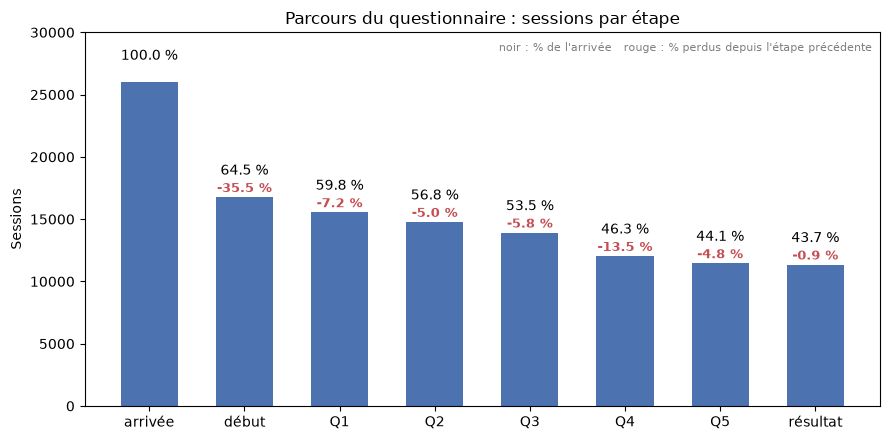

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(funnel["etape"], funnel["n"], color="#4C72B0", width=0.6)
for i, row in funnel.iterrows():
    ax.text(i, row["n"] + 1800, f"{row['pct%_arrivee']:.1f} %", ha="center")
    if i > 0:
        ax.text(i, row["n"] + 400, f"-{row['pct%_perdus']:.1f} %",
                ha="center", color="#C44E52", fontsize=9, fontweight="bold")
ax.set_ylim(0, 30000)
ax.set_title("Parcours du questionnaire : sessions par étape")
ax.set_ylabel("Sessions")
ax.text(0.99, 0.95, "noir : % de l'arrivée   rouge : % perdus depuis l'étape précédente",
        transform=ax.transAxes, ha="right", fontsize=8, color="gray")
plt.tight_layout()
plt.savefig("figures/01_funnel.png", dpi=150)
plt.show()

44 % des visiteurs vont jusqu'au résultat. Les deux plus grosses pertes : 35 % repartent sans commencer, et 13,5 % abandonnent entre Q3 et Q4 (deux fois plus qu'aux autres questions). La Q4 est la seule question sur le mode de vie (activité physique) et la seule à 4 choix :  on peut tester une version simplifiée de la Q4.

### Par appareil
Le parcours se passe-t-il aussi bien sur mobile que sur ordinateur ?

In [35]:
query = """
    SELECT device_type,
           COUNT(*)                    AS sessions,
           SUM(started::INT)           AS debut,
           SUM((nb_answers >= 3)::INT) AS atteint_q3,
           SUM((nb_answers >= 4)::INT) AS atteint_q4,
           SUM(completed::INT)         AS resultat
    FROM sessions
    GROUP BY device_type
    ORDER BY sessions DESC
"""
funnel_appareil = con.sql(query).df()
funnel_appareil

,device_type,sessions,debut,atteint_q3,atteint_q4,resultat
0,mobile,16772,10518.0,8555.0,7108.0,6660.0
1,desktop,7863,5383.0,4648.0,4278.0,4072.0
2,tablet,1365,873.0,717.0,658.0,625.0


In [36]:
funnel_appareil = funnel_appareil.astype({c: int for c in funnel_appareil.columns if c != "device_type"})
funnel_appareil["pct_trafic"]            = (100 * funnel_appareil["sessions"] / funnel_appareil["sessions"].sum()).round(1)
funnel_appareil["pct_debut"]             = (100 * funnel_appareil["debut"] / funnel_appareil["sessions"]).round(1)
funnel_appareil["pct_resultat_si_debut"] = (100 * funnel_appareil["resultat"] / funnel_appareil["debut"]).round(1)
funnel_appareil["pct_perdus_q3_q4"]      = (100 - 100 * funnel_appareil["atteint_q4"] / funnel_appareil["atteint_q3"]).round(1)

In [37]:
funnel_appareil[["device_type", "sessions", "pct_trafic", "debut", "pct_debut",
          "atteint_q3", "atteint_q4", "pct_perdus_q3_q4",
          "resultat", "pct_resultat_si_debut"]]

,device_type,sessions,pct_trafic,debut,pct_debut,atteint_q3,atteint_q4,pct_perdus_q3_q4,resultat,pct_resultat_si_debut
0,mobile,16772,64.5,10518,62.7,8555,7108,16.9,6660,63.3
1,desktop,7863,30.2,5383,68.5,4648,4278,8.0,4072,75.6
2,tablet,1365,5.2,873,64.0,717,658,8.2,625,71.6


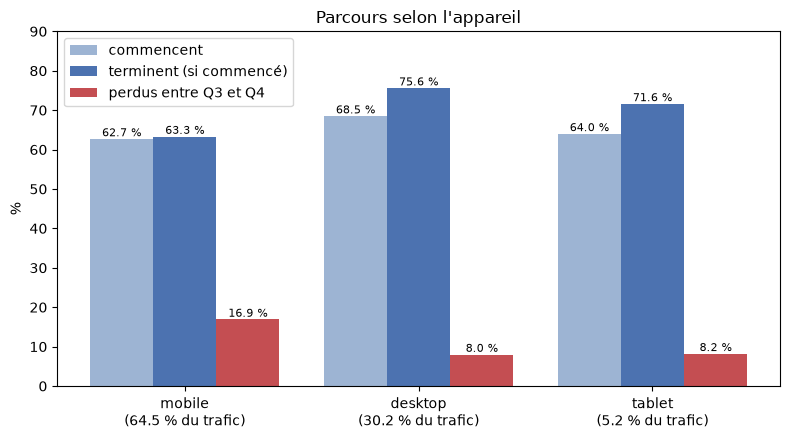

In [42]:
import numpy as np

indicateurs = {
    "pct_debut":             ("commencent",              "#9DB4D3"),
    "pct_resultat_si_debut": ("terminent (si commencé)", "#4C72B0"),
    "pct_perdus_q3_q4":      ("perdus entre Q3 et Q4",   "#C44E52"),
}

x = np.arange(len(funnel_appareil))
largeur = 0.27


fig, ax = plt.subplots(figsize=(8, 4.5))
for k, (col, (nom, couleur)) in enumerate(indicateurs.items()):
    barres = ax.bar(x + (k - 1) * largeur, funnel_appareil[col], largeur, label=nom, color=couleur)
    ax.bar_label(barres, fmt="%.1f %%", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"{d}\n({t:.1f} % du trafic)"
                    for d, t in zip(funnel_appareil["device_type"], funnel_appareil["pct_trafic"])])
ax.set_ylim(0, 90)
ax.set_ylabel("%")
ax.set_title("Parcours selon l'appareil")
ax.legend()
plt.tight_layout()
plt.savefig("figures/02_parcours_appareil.png", dpi=150)
plt.show()

Le mobile (65 % du trafic) perd deux fois plus de monde entre Q3 et Q4 que l'ordinateur (16.9 % contre 8 %), et termine moins souvent une fois le questionnaire commencé (63.3 % contre 75.6 %). Le décrochage à la Q4 vient donc surtout du mobile : peut-être la taille de  l'écran est la première chose à vérifier.

## 2. Canaux d'acquisition
Quels canaux apportent des questionnaires terminés, et pas seulement du trafic ?

### Par source

In [49]:
query = """
    SELECT acquisition_source,
           COUNT(*)                                           AS sessions,
           SUM(completed::INT)                                AS resultat,
           SUM((outcome_category = 'possible_risk')::INT)     AS possible_risk
    FROM sessions
    GROUP BY acquisition_source
    ORDER BY sessions DESC
"""
canaux = con.sql(query).df()

In [50]:
canaux = canaux.astype({c: int for c in canaux.columns if c != "acquisition_source"})
canaux["pct_trafic"]        = (100 * canaux["sessions"] / canaux["sessions"].sum()).round(1)
canaux["pct_resultat"]      = (100 * canaux["resultat"] / canaux["sessions"]).round(1)
canaux["pct_possible_risk"] = (100 * canaux["possible_risk"] / canaux["resultat"]).round(1)
canaux

,acquisition_source,sessions,resultat,possible_risk,pct_trafic,pct_resultat,pct_possible_risk
0,google_organic,7490,3228,591,28.8,43.1,18.3
1,google_ads,6375,2489,723,24.5,39.0,29.0
2,social,3618,1045,156,13.9,28.9,14.9
3,ai_assistant,2729,1444,205,10.5,52.9,14.2
4,referral,1790,1081,224,6.9,60.4,20.7
5,email,1707,1105,194,6.6,64.7,17.6
6,direct,1617,711,134,6.2,44.0,18.8
7,other,674,254,49,2.6,37.7,19.3


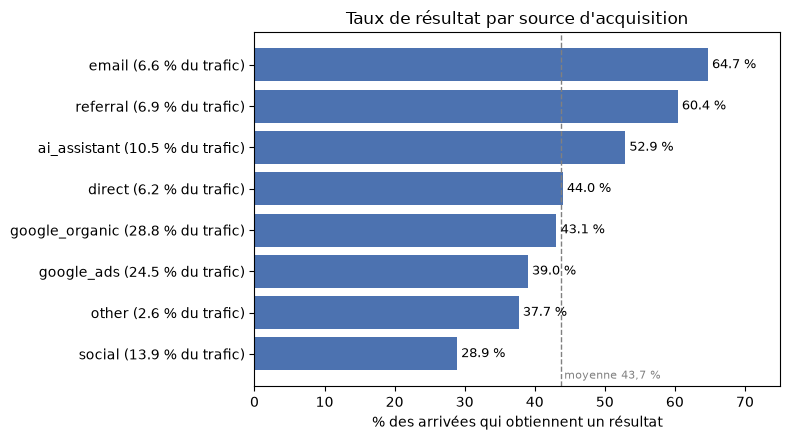

In [51]:
c = canaux.sort_values("pct_resultat")

fig, ax = plt.subplots(figsize=(8, 4.5))
barres = ax.barh([f"{s} ({t:.1f} % du trafic)" for s, t in zip(c["acquisition_source"], c["pct_trafic"])],
                 c["pct_resultat"], color="#4C72B0")
ax.bar_label(barres, fmt="%.1f %%", padding=3, fontsize=9)
ax.axvline(43.7, color="gray", linestyle="--", linewidth=1)
ax.text(44.2, -0.6, "moyenne 43,7 %", color="gray", fontsize=8)
ax.set_xlim(0, 75)
ax.set_xlabel("% des arrivées qui obtiennent un résultat")
ax.set_title("Taux de résultat par source d'acquisition")
plt.tight_layout()
plt.savefig("figures/03_resultat_par_source.png", dpi=150)
plt.show()

Google (organic + ads) apporte la moitié du trafic, mais l'email et le referral transforment le mieux respectivement 64.7% et 60.4 % de résultats contre 39% et 43.1 % de google ads et organic. Les assistants IA font mieux que Google (52.9 %) malgré un trafic modeste. Les réseaux sociaux sont le canal le plus faible (28.9 %). Google Ads ramène la plus forte part de `possible_risk` (29 %).

### Par campagne
Quelles campagnes produisent des résultats, et lesquelles touchent le public concerné ?

In [52]:
query = """
    SELECT campaign_name,
           COUNT(*)                                       AS sessions,
           SUM(completed::INT)                            AS resultat,
           SUM((outcome_category = 'possible_risk')::INT) AS possible_risk
    FROM sessions
    GROUP BY campaign_name
    ORDER BY sessions DESC
"""
campagnes = con.sql(query).df()
campagnes = campagnes.astype({c: int for c in campagnes.columns if c != "campaign_name"})
campagnes["pct_trafic"]        = (100 * campagnes["sessions"] / campagnes["sessions"].sum()).round(1)
campagnes["pct_resultat"]      = (100 * campagnes["resultat"] / campagnes["sessions"]).round(1)
campagnes["pct_possible_risk"] = (100 * campagnes["possible_risk"] / campagnes["resultat"]).round(1)
campagnes

,campaign_name,sessions,resultat,possible_risk,pct_trafic,pct_resultat,pct_possible_risk
0,no_campaign,14081,6602,1179,54.2,46.9,17.9
1,diabetes_awareness_general,3422,1554,269,13.2,45.4,17.3
2,diabetes_social_awareness,3345,954,141,12.9,28.5,14.8
3,diabetes_45plus,3337,1252,494,12.8,37.5,39.5
4,diabetes_retargeting,1815,995,193,7.0,54.8,19.4


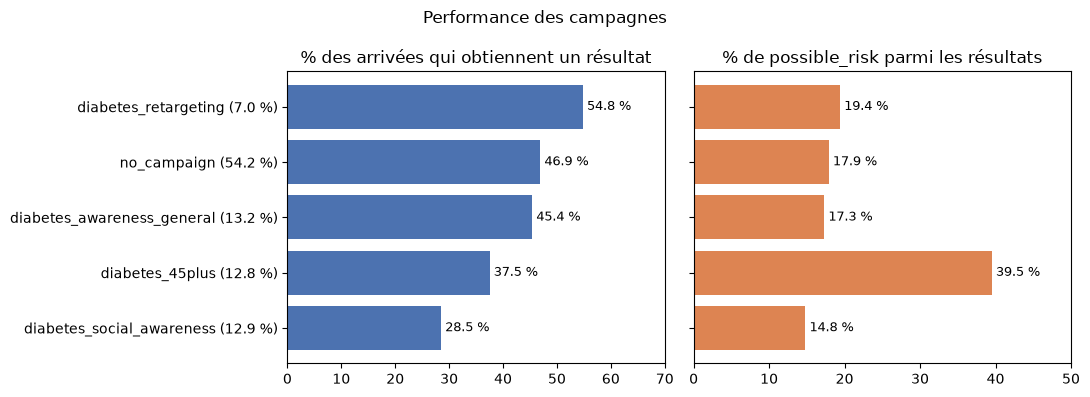

In [60]:
c = campagnes.sort_values("pct_resultat")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

b1 = ax1.barh([f"{s} ({t:.1f} %)" for s, t in zip(c["campaign_name"], c["pct_trafic"])], c["pct_resultat"], color="#4C72B0")
ax1.bar_label(b1, fmt="%.1f %%", padding=3, fontsize=9)
ax1.set_xlim(0, 70)
ax1.set_title("% des arrivées qui obtiennent un résultat")

b2 = ax2.barh([f"{s} ({t:.1f} %)" for s, t in zip(c["campaign_name"], c["pct_trafic"])], c["pct_possible_risk"], color="#DD8452")
ax2.bar_label(b2, fmt="%.1f %%", padding=3, fontsize=9)
ax2.set_xlim(0, 50)
ax2.set_title("% de possible_risk parmi les résultats")

plt.suptitle("Performance des campagnes")
plt.tight_layout()
plt.savefig("figures/04_campagnes.png", dpi=150)
plt.show()

`diabetes_45plus` touche le mieux le public concerné : 39.5 % de `possible_risk`, deux fois plus que les autres campagnes, soit 21.7 % de tous les `possible_risk` avec 12.8 % du trafic. Elle explique la forte part de `possible_risk` de Google Ads. `diabetes_social_awareness` est la plus faible sur les deux plans (28.5 % de résultats, 14.8 % de `possible_risk`). Le retargeting transforme le mieux (54.8 %).